<a href="https://colab.research.google.com/github/KwancheolShin/introduction-to-deep-learning/blob/main/%ED%95%99%EC%8A%B5%EA%B4%80%EB%A0%A8%EA%B8%B0%EC%88%A0%EB%93%A4/code/mnist_torch.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# 학습 관련 기술: 같은 MNIST 분류기를 PyTorch로

NumPy 최종 코드와 같은 설정을 PyTorch로 구현한다 (`BatchNorm1d`, `kaiming_normal_`, `AdamW`, `state_dict`). 원본: `mnist_torch.py`

* 셀을 위에서부터 차례로 실행한다 (Shift+Enter). 앞 셀에서 만든 변수는 다음 셀에서 그대로 쓸 수 있다.
* Colab에서 GPU를 쓰려면 메뉴의 **런타임 → 런타임 유형 변경 → GPU**를 고른다. CPU에서도 동작한다.
* 그림은 작업 폴더의 `figures/`에도 저장된다 (Colab의 작업 폴더는 `/content`이며, 세션이 끝나면 지워진다).


이 노트북은 같은 폴더의 모듈 `mnist_data.py`을 불러 쓴다. 아래 셀은 그 파일이 없으면 (Colab처럼) 수업 GitHub 저장소에서 내려받는다.

In [1]:
import os, urllib.request, urllib.parse
REPO = "https://raw.githubusercontent.com/KwancheolShin/introduction-to-deep-learning/main/"
for f in ['mnist_data.py']:
    if not os.path.exists(f):
        urllib.request.urlretrieve(REPO + urllib.parse.quote("학습관련기술들/code/" + f), f)
        print("downloaded", f)
print("ready:", [f for f in ['mnist_data.py'] if os.path.exists(f)])

downloaded mnist_data.py
ready: ['mnist_data.py']


In [2]:
# Week: Techniques for Training -- the same MNIST classifier in PyTorch
#
#   Everything we built by hand has a PyTorch counterpart:
#     Affine                     -> nn.Linear            (its weight is (out, in): the TRANSPOSE of our W)
#     Relu                       -> nn.ReLU
#     BatchNormalization         -> nn.BatchNorm1d       (momentum=0.1 means our momentum 0.9)
#     Dropout                    -> nn.Dropout           (inverted dropout, the same as ours)
#     SoftmaxWithCrossEntropy    -> nn.CrossEntropyLoss  (takes the scores and class INDICES, not one-hot)
#     backward() of every layer  -> loss.backward()      (autograd records the computational graph)
#     optimizers.py              -> torch.optim.SGD, torch.optim.Adam, torch.optim.AdamW, ...
#     train_flg=True / False     -> model.train() / model.eval()
#     weight_init_std="he"       -> nn.init.kaiming_normal_
#
#   * uses mnist_data.py in the same folder: the SAME train / validation / test split as our numpy code
# Figures are saved to ../figures/ (next to main.tex), wherever this file is run from

import os
import copy
import numpy as np
import matplotlib.pyplot as plt
import torch
from torch import nn
from torch.utils.data import TensorDataset, DataLoader

from mnist_data import load_mnist_split

In [3]:
FIG_DIR = "figures"          # notebook: save next to the notebook (the .py version uses the folder of the script, via __file__)
os.makedirs(FIG_DIR, exist_ok=True)

torch.manual_seed(0)
device = "cuda" if torch.cuda.is_available() else "cpu"
print(f"device: {device}")

# =====================================================
# Data: numpy arrays -> tensors -> DataLoader (shuffling and mini-batches for us)
# =====================================================
x_train, t_train, x_val, t_val, x_test, t_test = load_mnist_split()   # 55000 / 5000 / 10000


def to_dataset(x, t):
    """images (N, 784) and one-hot labels (N, 10) -> a dataset of (image, class index)"""
    return TensorDataset(torch.tensor(x, dtype=torch.float32),
                         torch.tensor(np.argmax(t, axis=1)))


train_loader = DataLoader(to_dataset(x_train, t_train), batch_size=100, shuffle=True)
val_loader   = DataLoader(to_dataset(x_val, t_val), batch_size=1000)
test_loader  = DataLoader(to_dataset(x_test, t_test), batch_size=1000)

device: cuda


In [4]:
# =====================================================
# Model: [Linear -> BatchNorm -> ReLU -> (Dropout)] x k -> Linear,  He initialization
# =====================================================
def make_mlp(hidden=(100, 100, 100, 100), use_batchnorm=True, dropout_ratio=0.0):
    layers, n_in = [], 784
    for n_out in hidden:
        layers.append(nn.Linear(n_in, n_out))
        if use_batchnorm:
            layers.append(nn.BatchNorm1d(n_out))
        layers.append(nn.ReLU())
        if dropout_ratio > 0:
            layers.append(nn.Dropout(dropout_ratio))
        n_in = n_out
    layers.append(nn.Linear(n_in, 10))            # scores U; softmax is inside the loss
    model = nn.Sequential(*layers)
    for m in model.modules():
        if isinstance(m, nn.Linear):
            nn.init.kaiming_normal_(m.weight, nonlinearity="relu")   # He: std = sqrt(2 / n_in)
            nn.init.zeros_(m.bias)
    return model

model = make_mlp().to(device)
print(model)
print("number of parameters:", sum(p.numel() for p in model.parameters()))


# model = nn.Sequential(
#     nn.Linear(784, 100), nn.BatchNorm1d(100), nn.ReLU(),   # (N, 784) -> (N, 100)
#     nn.Linear(100, 100), nn.BatchNorm1d(100), nn.ReLU(),
#     nn.Linear(100, 100), nn.BatchNorm1d(100), nn.ReLU(),
#     nn.Linear(100, 100), nn.BatchNorm1d(100), nn.ReLU(),
#     nn.Linear(100, 10),                                    # scores U; softmax is inside the loss
# ).to(device)

# for m in model.modules():                                  # He initialization
#     if isinstance(m, nn.Linear):
#         nn.init.kaiming_normal_(m.weight, nonlinearity="relu")   # std = sqrt(2 / n_in)
#         nn.init.zeros_(m.bias)

loss_fn = nn.CrossEntropyLoss()                  # softmax + cross-entropy, averaged over the batch

# AdamW: decay only the weights W (2-D), not B, gamma, beta (1-D) -- the same choice as our code
decay     = [p for p in model.parameters() if p.dim() == 2]
no_decay  = [p for p in model.parameters() if p.dim() == 1]
optimizer = torch.optim.AdamW([{"params": decay,    "weight_decay": 0.01},
                               {"params": no_decay, "weight_decay": 0.0 }], lr=0.001)

# The usual one-line form (uncomment to compare): decays EVERY parameter, also B, gamma, beta
# optimizer = torch.optim.AdamW(model.parameters(), lr=1e-3, weight_decay=0.01)

# =====================================================
# Training and evaluation
# =====================================================
def train_one_epoch(model, loader):
    model.train()                                 # BatchNorm: batch statistics, Dropout: on
    total_loss, n = 0.0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        loss   = loss_fn(model(xb), yb)           # forward: the graph is recorded
        optimizer.zero_grad()                     # gradients ADD UP in .grad, so clear them first
        loss.backward()                           # backward: dL/dW for every parameter
        optimizer.step()                          # = optimizer.update(params, grads)
        total_loss += loss.item() * len(yb)
        n += len(yb)
    return total_loss / n


@torch.no_grad()                                  # no graph needed: faster, less memory
def accuracy(model, loader):
    model.eval()                                  # BatchNorm: running averages, Dropout: off
    correct, n = 0, 0
    for xb, yb in loader:
        xb, yb = xb.to(device), yb.to(device)
        correct += (model(xb).argmax(dim=1) == yb).sum().item()
        n += len(yb)
    return correct / n

Sequential(
  (0): Linear(in_features=784, out_features=100, bias=True)
  (1): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (2): ReLU()
  (3): Linear(in_features=100, out_features=100, bias=True)
  (4): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (5): ReLU()
  (6): Linear(in_features=100, out_features=100, bias=True)
  (7): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (8): ReLU()
  (9): Linear(in_features=100, out_features=100, bias=True)
  (10): BatchNorm1d(100, eps=1e-05, momentum=0.1, affine=True, track_running_stats=True)
  (11): ReLU()
  (12): Linear(in_features=100, out_features=10, bias=True)
)
number of parameters: 110610


In [5]:
epochs = 15
history = {"loss": [], "train": [], "val": []}
best_val, best_state = 0.0, None
for epoch in range(1, epochs + 1):
    history["loss"].append(train_one_epoch(model, train_loader))
    history["train"].append(accuracy(model, train_loader))
    history["val"].append(accuracy(model, val_loader))
    print(f"epoch {epoch:2d} | loss {history['loss'][-1]:.4f} | "
          f"train acc {history['train'][-1]:.4f} | val acc {history['val'][-1]:.4f}")
    if history["val"][-1] > best_val:             # keep the epoch with the best VALIDATION accuracy
        best_val, best_epoch = history["val"][-1], epoch
        best_state = copy.deepcopy(model.state_dict())
        # Checkpoint file of the best epoch (uncomment to use): model AND optimizer, so training can resume
        # torch.save({"epoch": epoch, "val_acc": best_val,
        #             "model": model.state_dict(),            # parameters + BatchNorm running statistics
        #             "optimizer": optimizer.state_dict()},   # AdamW's m, v and step counts
        #            "ckpt.pt")

# Only at the very end: the test data, ONCE, with the chosen model
model.load_state_dict(best_state)
print(f"chosen epoch {best_epoch}: val acc {best_val:.4f}, test acc {accuracy(model, test_loader):.4f}")
# torch.save(model.state_dict(), "mnist_torch.pt")   # to keep only the trained weights

# Loading the checkpoint later (uncomment to use): build the SAME model first, then fill in the values
# ckpt = torch.load("ckpt.pt", map_location=device, weights_only=True)
# model = make_mlp().to(device)
# model.load_state_dict(ckpt["model"])
# print(f"loaded epoch {ckpt['epoch']}: val acc {ckpt['val_acc']:.4f}, test acc {accuracy(model, test_loader):.4f}")
# # only to CONTINUE training: rebuild the optimizer for the new model (as above), then load its state
# decay    = [p for p in model.parameters() if p.dim() == 2]
# no_decay = [p for p in model.parameters() if p.dim() == 1]
# optimizer = torch.optim.AdamW([{"params": decay,    "weight_decay": 0.01},
#                                {"params": no_decay, "weight_decay": 0.0 }], lr=0.001)
# optimizer.load_state_dict(ckpt["optimizer"])

epoch  1 | loss 0.2994 | train acc 0.9724 | val acc 0.9654


epoch  2 | loss 0.1074 | train acc 0.9814 | val acc 0.9704


epoch  3 | loss 0.0746 | train acc 0.9875 | val acc 0.9738


epoch  4 | loss 0.0608 | train acc 0.9914 | val acc 0.9748


epoch  5 | loss 0.0468 | train acc 0.9921 | val acc 0.9780


epoch  6 | loss 0.0414 | train acc 0.9944 | val acc 0.9782


... (6 outputs left out)

epoch 13 | loss 0.0193 | train acc 0.9979 | val acc 0.9794


epoch 14 | loss 0.0182 | train acc 0.9979 | val acc 0.9814


epoch 15 | loss 0.0175 | train acc 0.9977 | val acc 0.9808


chosen epoch 12: val acc 0.9828, test acc 0.9780


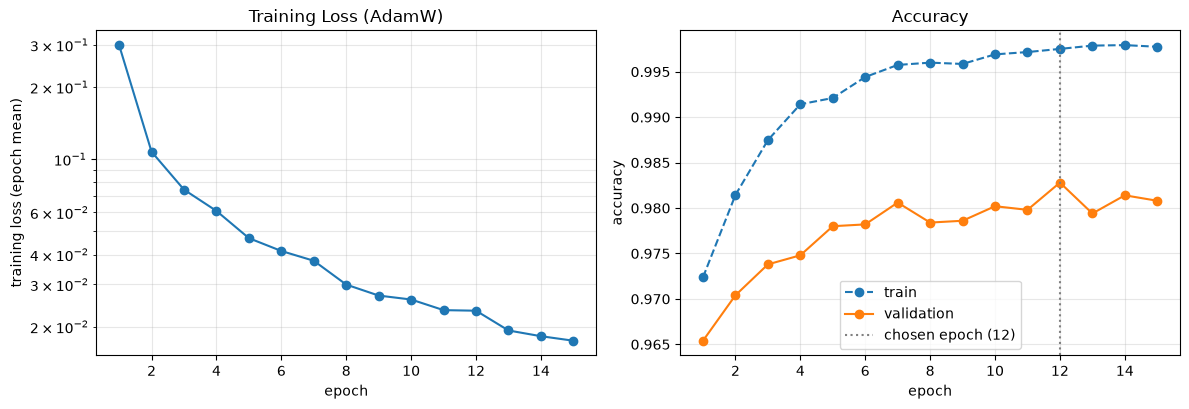

In [6]:
# =====================================================
# Figure
# =====================================================
fig, ax = plt.subplots(1, 2, figsize=(12, 4.2))
ax[0].plot(range(1, epochs + 1), history["loss"], "o-")
ax[0].set_yscale("log")
ax[0].set(xlabel="epoch", ylabel="training loss (epoch mean)", title="Training Loss (AdamW)")
ax[0].grid(True, which="both", alpha=0.3)
ax[1].plot(range(1, epochs + 1), history["train"], "o--", label="train")
ax[1].plot(range(1, epochs + 1), history["val"], "o-", label="validation")
ax[1].axvline(best_epoch, color="gray", linestyle=":", label=f"chosen epoch ({best_epoch})")
ax[1].set(xlabel="epoch", ylabel="accuracy", title="Accuracy")
ax[1].grid(True, alpha=0.3)
ax[1].legend()
fig.tight_layout()
fig.savefig(os.path.join(FIG_DIR, "torch_mnist.png"), dpi=200, bbox_inches="tight")
plt.show()
plt.close(fig)